In [1]:
import geopandas as gpd
import pandas as pd
import sys

from pathlib import Path

REPO_ROOT = Path.cwd().parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
src_dir = Path('~').expanduser() / "OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/"
excel_path = "/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/data_correlation.xlsx"

In [3]:
wage_df = pd.read_csv(REPO_ROOT / 'output/wage_by_command_unit.csv')
productivity_df = pd.read_csv(REPO_ROOT / 'output/group_productivity.csv', index_col=0)

In [4]:
map_df = wage_df.merge(productivity_df, on='area', how='left')

In [5]:
command_gdf = gpd.read_file(src_dir / 'Final2_Command_Area.shp')
conversion_df = pd.read_excel(excel_path, sheet_name='command_area')

mapping = conversion_df.merge(
    command_gdf[['Name', 'OBJECTID', 'geometry']],
    left_on = 'area_map_name',
    right_on = 'OBJECTID',
).set_index('area_name')["Name"]

# mapping = (
#     command_gdf.merge(
#         conversion_df[['area_map_name', 'area_name']],
#         left_on='OBJECTID',
#         right_on='area_map_name'
#     )
#     .set_index('Name')['area_map_name']
# )

# excel_salinity_df['area'] = excel_salinity_df['area'].map(mapping)

In [6]:
map_df['area_name'] = map_df['area'].map(mapping)
map_df['geometry'] = map_df['area_name'].map(command_gdf.set_index('Name')['geometry'])
map_gdf = gpd.GeoDataFrame(map_df, geometry='geometry')
map_gdf

,area,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,...,agricultural_productivity_90,water_procuctivity_90,agricultural_productivity_no_salinity_90,water_procuctivity_no_salinity_90,agricultural_productivity_95,water_procuctivity_95,agricultural_productivity_no_salinity_95,water_procuctivity_no_salinity_95,area_name,geometry
0,Blk_Air_1,408.260943,2447.147973,416.677738,2518.268462,402.669884,2559.302853,390.364611,2580.051670,379.276596,...,124353.473415,0.063353,159818.668522,0.081421,92560.506239,0.049775,159818.668522,0.085944,الرشيدية_ومباشر غرب رشيد,"POLYGON ((247461.461 3475172.069, 247509.794 3..."
1,Blk_Air_2,265.039323,2537.057602,279.859787,2571.406985,282.397402,2565.954466,285.165879,2610.998665,268.155875,...,115829.161032,0.017949,144562.612960,0.022401,92040.745691,0.015691,144562.614049,0.024645,الرياح البحيرى,"POLYGON ((261305.4 3444700.118, 263931.396 344..."
2,Blk_Air_6,NaN,2364.358670,NaN,2369.313832,NaN,2375.509000,NaN,2355.208550,NaN,...,99658.819188,0.053430,122190.125053,0.065509,61910.682841,0.035036,122190.125053,0.069149,الخيام,"POLYGON ((406128.564 2896644.369, 405851.638 2..."
3,Blk_Air_7,497.728262,2248.533481,472.160511,2279.299200,475.013047,2317.988823,474.614806,2295.921435,505.878393,...,105091.195726,0.006601,128425.325084,0.008067,68758.264071,0.004559,128425.325084,0.008515,نجع حمادى الغربية,"MULTIPOLYGON (((413357.904 2888052.363, 413605..."
4,Blk_Air_8,502.369987,2320.565571,503.915949,2328.323529,503.895144,2335.988811,521.573689,2284.731997,536.971587,...,105840.255533,0.021422,131310.551141,0.026577,64698.298308,0.013823,131310.551141,0.028054,نجع حمادى الشرقية,"POLYGON ((302966.787 3027653.613, 303344.583 3..."
5,Blk_Air_9,NaN,1797.509180,NaN,1767.089264,NaN,1773.090397,NaN,1715.490667,NaN,...,90064.406985,0.014132,108039.177897,0.016952,57321.536204,0.009494,108039.177897,0.017894,الكلابية,"POLYGON ((431202.296 2887164.225, 431117.995 2..."
6,Blk_Air_11,323.828550,2373.505399,325.893103,2344.347002,336.898308,2297.124522,352.657625,2290.141044,334.753267,...,96704.211409,0.052937,132910.925783,0.072757,55721.948742,0.032198,132910.925783,0.076799,ترعة الصف,"POLYGON ((335563.849 3315535.74, 335849.138 33..."
7,Blk_Air_12,639.442336,2418.701067,629.313177,2459.883604,636.604942,2475.704925,619.106248,2415.535015,615.252653,...,119974.037900,0.022619,174155.885083,0.032834,72847.952307,0.014387,174155.885083,0.034395,البحر الصغير,"MULTIPOLYGON (((373025.884 3453005.123, 372789..."
8,Blk_Air_13,231.958808,2259.748223,207.502736,2126.657752,205.987521,2131.171492,206.705920,2115.964820,206.825002,...,17999.664148,0.116309,24981.366149,0.161423,9655.033553,0.065854,24981.366149,0.170391,النجايل,"POLYGON ((312678.401 3354891.789, 312809.524 3..."
9,Blk_Air_14,1431.957740,2377.690328,1432.079996,2411.736798,1411.559329,2431.403291,1398.626243,2404.053485,1435.604633,...,127817.817235,0.286481,181531.813619,0.406871,104271.712800,0.246690,181531.818253,0.429475,قنال العنانية,"MULTIPOLYGON (((383065.59 3474016.918, 383059...."


In [17]:
command_gdf['area'] = command_gdf["Name"].map(mapping)
command_gdf

InvalidIndexError: Reindexing only valid with uniquely valued Index objects

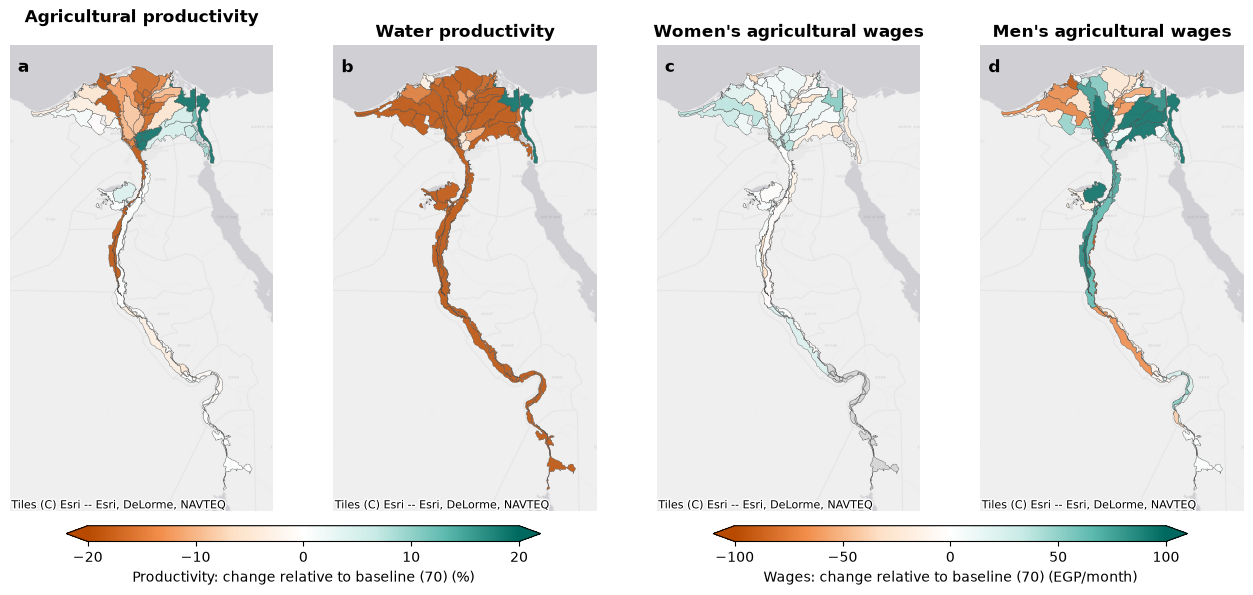

<Figure size 640x480 with 0 Axes>

In [8]:
import contextily as cx
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

baseline = '70'
scenarios = ['50']
for scenario in scenarios:
    # (column prefix, title, colour-scale group)
    panels = [
        ('agricultural_productivity', 'Agricultural productivity', 'productivity'),
        ('water_procuctivity', 'Water productivity', 'productivity'),  # column name typo originates from the source data
        ('female', "Women's agricultural wages", 'wages'),
        ('male', "Men's agricultural wages", 'wages'),
    ]
    # productivity is shown as relative change (%), wages as absolute change (EGP per month)
    # symmetric colour limits per group; the wage scale is shared between women and men
    vlims = {'productivity': 20, 'wages': 100}
    cbar_labels = {
        'productivity': f'Productivity: change relative to baseline ({baseline}) (%)',
        'wages': f'Wages: change relative to baseline ({baseline}) (EGP/month)',
    }

    plot_gdf = map_gdf.to_crs(epsg=3857)  # web mercator, matches the basemap tiles
    for var, _, group in panels:
        diff = plot_gdf[f'{var}_{scenario}'] - plot_gdf[f'{var}_{baseline}']
        plot_gdf[f'{var}_diff'] = diff / plot_gdf[f'{var}_{baseline}'] * 100 if group == 'productivity' else diff

    cmap = LinearSegmentedColormap.from_list(
        'orange_teal', ['#b84a00', '#f28e4b', '#fde0c5', '#ffffff', '#c9ebe6', '#5bb8ad', '#00695f']
    )
    norms = {group: Normalize(vmin=-v, vmax=v) for group, v in vlims.items()}

    minx, miny, maxx, maxy = plot_gdf.total_bounds
    pad = 0.05 * max(maxx - minx, maxy - miny)

    fig, axes = plt.subplots(1, 4, figsize=(16, 6.5), sharex=True, sharey=True)
    for ax, (var, title, group), letter in zip(axes, panels, 'abcd'):
        ax.set_xlim(minx - pad, maxx + pad)
        ax.set_ylim(miny - pad, maxy + pad)
        plot_gdf.plot(
            column=f'{var}_diff', ax=ax, cmap=cmap, norm=norms[group], alpha=0.85,
            edgecolor='0.3', linewidth=0.3,
            missing_kwds={'color': 'lightgrey', 'edgecolor': '0.3', 'linewidth': 0.3},
        )
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, crs=plot_gdf.crs, zoom=8)
        ax.set_title(title, fontweight='bold')
        ax.text(0.03, 0.97, letter, transform=ax.transAxes, va='top', fontweight='bold', fontsize=12)
        ax.set_axis_off()

    # one horizontal colorbar per colour-scale group, centred under its panels
    for group, group_axes in [('productivity', axes[:2]), ('wages', axes[2:])]:
        v = vlims[group]
        cbar = fig.colorbar(
            ScalarMappable(norm=norms[group], cmap=cmap), ax=list(group_axes), orientation='horizontal',
            fraction=0.04, pad=0.03, aspect=30, shrink=0.8, extend='both',
        )
        cbar.set_label(cbar_labels[group])
        cbar.set_ticks([-v, -v / 2, 0, v / 2, v])
    plt.show()
    plt.savefig(FIGURE_DIR / f'map_plots_{baseline}_{scenario}.png')